# Walkthrough: a cloud-free Sentinel-2 mosaic with Steps 2-4

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/buckai-observatory/Automated-Cloud-Removal-and-Seamless-Satellite-Image-Mosaicking-Pipeline/blob/main/notebooks/sentinel2_walkthrough.ipynb)

The pipeline turns several overlapping, partly cloudy satellite scenes into one
seamless mosaic and then replaces the clouds with clear pixels from other
acquisitions. It has four steps:

| Step | Folder | What it does |
|---|---|---|
| 1 | `step1_color_balance/` | Matches the colours of the scenes (ERDAS IMAGINE models; not run here) |
| 2 | `step2_mosaic/` | Finds a seamline between each pair of overlapping scenes and mosaics the multispectral (XS) scenes and their cloud masks |
| 3 | `step3_pan_mosaic/` | Mosaics the panchromatic (Pan) scenes along the same seamlines |
| 4 | `step4_cloud_removal/` | Fills the clouds in both mosaics with pixels from mostly clear candidate scenes |

This notebook runs Steps 2-4 on six public Sentinel-2 scenes over central-western
Taiwan (about 22 km x 22 km) and shows the inputs, the intermediate products and
the result of each step. Step 1 needs ERDAS IMAGINE, so the scenes go into
Step 2 without colour balancing.

**How to use it.** Run the cells from top to bottom (*Run all*). Each code cell
has a text cell above it that says what the code does and, for figures, what to
look for. On Colab the whole notebook takes about 5 minutes and nothing has to
be installed on your computer.

## 1. Setup

### 1.1 Install the pipeline (Colab) or use this repository (local)

**What this cell does.** On Colab, it clones the repository to
`/content/cloud-mosaic`, installs the GDAL command-line tools (`gdal-bin`;
Steps 2 and 3 call `gdal_translate` and `gdalwarp`) and the Python packages in
`requirements.txt`. Colab already has a newer OpenCV, installed under several
package names; the cell removes those first, because the pipeline needs OpenCV
older than 4.11 (`cv2.seamlessClone`, used in Step 4, changed in 4.11). This
takes about one minute.

Run locally, the cell installs nothing. It uses the repository that contains
this notebook. Install the environment first, as described in the README
(`pixi run --locked -e notebook lab` opens this notebook in the locked
environment).

The cell ends by printing the OpenCV and GDAL versions, so you can check that
the installation worked.

In [1]:
import pathlib
import subprocess
import sys

IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/buckai-observatory/Automated-Cloud-Removal-and-Seamless-Satellite-Image-Mosaicking-Pipeline.git"
BRANCH = "main"

def sh(command):
    """Run a shell command and stop with its output if it fails."""
    result = subprocess.run(command, shell=True, capture_output=True, text=True)
    if result.returncode != 0:
        print(result.stdout[-3000:], result.stderr[-3000:])
        raise RuntimeError(f"failed: {command}")

if IN_COLAB:
    REPO = pathlib.Path("/content/cloud-mosaic")
    if not REPO.exists():
        sh(f"git clone --depth 1 --branch {BRANCH} {REPO_URL} {REPO}")
    sh("apt-get -qq update && apt-get -qq install -y gdal-bin")
    sh("pip uninstall -y -q opencv-python opencv-python-headless opencv-contrib-python")
    sh(f"pip install -q -r {REPO}/requirements.txt")
else:
    REPO = pathlib.Path.cwd().resolve().parent   # notebooks/ -> repository root

import cv2
print("repository:", "/content/cloud-mosaic" if IN_COLAB else REPO.name)
print("OpenCV", cv2.__version__)
print(subprocess.run(["gdalinfo", "--version"], capture_output=True, text=True).stdout.strip())

repository: nbrun2
OpenCV 4.10.0
GDAL 3.13.3 "Iowa City", released 2026/08/13


### 1.2 Libraries, the demo functions and the working folders

**What this cell does.**

- It imports the libraries used for reading rasters (`rasterio`), tables
  (`pandas`) and figures (`matplotlib`).
- It loads `examples/sentinel2_demo/run_demo.py` as a module called `demo`.
  That script runs the same workflow from the command line; the notebook reuses
  its functions to download the data (`demo.download`), prepare the step folders
  (`demo.set_up_steps`, `demo.write_configs`), copy files between steps
  (`demo.copy_matching`) and summarise the result (`demo.check_results`).
- It defines the folders: everything goes into `demo_output/` in the repository
  (ignored by git): the downloaded data in `demo_output/data/` and one working
  folder per step in `demo_output/step2/`, `step3/` and `step4/`.
- It sets the figure style: bold text, thick black axes, and a colour palette
  that colour-blind readers can distinguish (Wong 2011), with different line
  styles in addition to colours.

In [2]:
import base64
import importlib.util
import io
import json
import shutil
import uuid

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
from IPython.display import HTML, display
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

spec = importlib.util.spec_from_file_location("run_demo", REPO / "examples" / "sentinel2_demo" / "run_demo.py")
demo = importlib.util.module_from_spec(spec)
spec.loader.exec_module(demo)

WORK = REPO / "demo_output"
DATA = WORK / "data"
S2, S3, S4 = WORK / "step2", WORK / "step3", WORK / "step4"

mpl.rcParams.update({
    "font.size": 12, "axes.labelsize": 13, "legend.fontsize": 11,
    "font.weight": "bold", "axes.labelweight": "bold",
    "axes.linewidth": 1.6, "axes.edgecolor": "black",
    "figure.dpi": 72, "savefig.dpi": 300,
})
WONG = ["#000000", "#E69F00", "#56B4E9", "#009E73", "#F0E442", "#0072B2", "#D55E00", "#CC79A7"]
LINESTYLES = ["-", "--", "-."]

### 1.3 Helper functions for the figures

**What this cell does.** It defines five small functions that the figure cells
below use. You do not need to change them.

- `stretch_limits(*files)`: the 2nd and 98th percentiles of the red, green and
  blue bands over all valid pixels of the given files. All images in a figure
  use the same limits, so their brightness can be compared directly.
- `show_rgb(ax, file, limits)`: draws a true-colour image (red, green, blue)
  in map coordinates (TWD97, in km), so that scenes with different extents line
  up. Pixels without data (value 0) are left white.
- `outline(ax, file, condition, colour)`: draws the outline of the pixels of a
  raster that meet a condition, for example the cloud pixels of a cloud mask.
- `label(ax, text)`: writes a panel label such as "(a)" in the top-left corner.
- `map_axes(ax, extent)`: sets the axis limits, equal scaling and the axis label.

In [3]:
def extent_km(src):
    b = src.bounds
    return [b.left / 1000, b.right / 1000, b.bottom / 1000, b.top / 1000]

def stretch_limits(*paths):
    values = []
    for p in paths:
        with rasterio.open(p) as src:
            rgb = src.read([3, 2, 1]).astype(float)
        valid = np.all(rgb > 0, axis=0)
        values.append(rgb[:, valid])
    v = np.concatenate(values, axis=1)
    return np.percentile(v, 2, axis=1), np.percentile(v, 98, axis=1)

def rgb_array(path, limits):
    """Stretched true-colour image (rows, cols, 4) with transparent no-data, and its extent in km."""
    lo, hi = limits
    with rasterio.open(path) as src:
        rgb = src.read([3, 2, 1]).astype(float)
        ext = extent_km(src)
    valid = np.all(rgb > 0, axis=0)
    img = np.clip((rgb - lo[:, None, None]) / (hi - lo)[:, None, None], 0, 1).transpose(1, 2, 0)
    return np.dstack([img, valid.astype(float)]), ext

def show_rgb(ax, path, limits):
    rgba, ext = rgb_array(path, limits)
    ax.imshow(rgba, extent=ext)
    return ext

def outline(ax, path, condition, color, linestyle="-", linewidth=1.4):
    with rasterio.open(path) as src:
        a = condition(src.read(1)).astype(float)
        ext = extent_km(src)
    x = np.linspace(ext[0], ext[1], a.shape[1])
    y = np.linspace(ext[3], ext[2], a.shape[0])
    ax.contour(x, y, a, levels=[0.5], colors=[color], linestyles=[linestyle], linewidths=linewidth)

def label(ax, text):
    ax.text(0.02, 0.98, text, transform=ax.transAxes, va="top", ha="left", fontweight="bold",
            bbox=dict(facecolor="white", edgecolor="black", linewidth=1.0, pad=2.5))

def map_axes(ax, ext):
    ax.set_xlim(ext[0], ext[1]); ax.set_ylim(ext[2], ext[3])
    ax.set_xlabel("x [km]"); ax.set_aspect("equal")
    ax.locator_params(nbins=4)

## 2. Input data

### 2.1 Download the six Sentinel-2 scenes

**What this cell does.** It downloads small subsets of six Sentinel-2 Level-2A
acquisitions from the public [Earth Search](https://earth-search.aws.element84.com/v1)
catalogue (no account is needed) and converts each one into the inputs the
pipeline expects. This takes about one minute and about 350 MB of disk space.
If the data are already in `demo_output/data/`, the download is skipped.

For each acquisition, the conversion writes three files:

- **XS scene** (`scenes/` or `candidates/`, e.g. `a0000001.img`): four bands
  (blue, green, red, near-infrared) at 20 m, reprojected to TWD97
  (`EPSG:3826`, the pipeline's default grid) and scaled to 12-bit values.
- **Pan scene** (`raw_pan/`, e.g. `A0000002.tif`): Sentinel-2 has no
  panchromatic band, so the mean of the three 10 m visible bands stands in for
  it. As for SPOT, the Pan file number is the XS file number plus one.
- **Cloud mask** (`cloud_masks/`, e.g. `a0000001_cloud.tif`; 255 = cloud,
  0 = clear): pixels that the Sentinel-2 scene classification labels as cloud
  shadow, medium- or high-probability cloud or thin cirrus, buffered by 200 m
  because the classification misses the haze at cloud edges.

The acquisitions have two roles:

- **Three scenes to mosaic** (`a0000001`, `a0000003`, `a0000005`; 26-30 % cloud).
  Real satellite scenes overlap only partly. To imitate that, each of these is cut
  to a tilted north-south strip, like a separate satellite swath; neighbouring
  strips overlap by about 3 km.
- **Three candidate scenes** (`a0000101`, `a0000103`, `a0000105`), mostly
  clear and covering the whole area. Step 4 copies pixels from them into the
  clouds.

The table lists the acquisitions with their dates.

In [4]:
if demo.missing_data(DATA):
    demo.download(DATA)
else:
    print("Data already downloaded in", DATA.relative_to(REPO))

scenes = [(name, item) for name, item, _ in demo.PRIMARY]
candidates = [(name, item) for name, item, _ in demo.CANDIDATES]
pd.DataFrame(
    [(n, i.split("_")[2], "mosaic") for n, i in scenes] + [(n, i.split("_")[2], "candidate") for n, i in candidates],
    columns=["file name", "acquisition date", "role"])

  a0000003 <- S2B_51QTG_20231126_0_L2A


    cloud cover 30%
  a0000001 <- S2A_51QTG_20231022_0_L2A


    cloud cover 27%
  a0000005 <- S2A_51QTG_20230922_0_L2A


    cloud cover 26%
  a0000101 <- S2A_51QTG_20231121_0_L2A


  a0000103 <- S2A_51QTG_20231101_0_L2A


  a0000105 <- S2A_51QTG_20231012_0_L2A


,file name,acquisition date,role
0,a0000003,20231126,mosaic
1,a0000001,20231022,mosaic
2,a0000005,20230922,mosaic
3,a0000101,20231121,candidate
4,a0000103,20231101,candidate
5,a0000105,20231012,candidate


### 2.2 Figure 1: the scenes to mosaic

**What this cell does.** It draws the three scenes to mosaic in true colour
(panels a-c), each with the outline of its cloud mask in orange, and the
footprints of all three in the demo area (panel d). All panels use the same
contrast stretch and the same map extent.

**What to look for.**

- The clouds (white, inside the orange outlines) are in different places in
  each scene. That is what makes it possible to fill them later.
- In panel (d), each strip overlaps its neighbour, and the boundaries of
  neighbouring strips cross at two points (top and bottom of the overlap).
  Step 2 needs these two crossing points: each seamline starts at one and ends
  at the other.

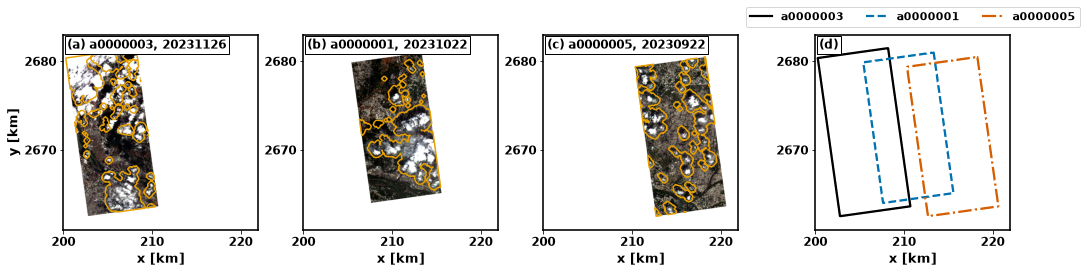

In [5]:
scene_files = [DATA / "scenes" / f"{n}.img" for n, _ in scenes]
mask_files = [DATA / "cloud_masks" / f"{n}_cloud.tif" for n, _ in scenes]
limits = stretch_limits(*scene_files)
aoi_km = [demo.AOI[0] / 1000, demo.AOI[2] / 1000, demo.AOI[1] / 1000, demo.AOI[3] / 1000]

fig, axes = plt.subplots(1, 4, figsize=(15, 5.2), constrained_layout=True)
for k, (ax, f, m, (name, item)) in enumerate(zip(axes, scene_files, mask_files, scenes)):
    show_rgb(ax, f, limits)
    outline(ax, m, lambda a: a > 0, WONG[1])
    map_axes(ax, aoi_km)
    label(ax, f"({'abc'[k]}) {name}, {item.split('_')[2]}")
axes[0].set_ylabel("y [km]")
ax = axes[3]
for k, f in enumerate(scene_files):
    outline(ax, f, lambda a: a > 0, WONG[[0, 5, 6][k]], LINESTYLES[k], 2.2)
map_axes(ax, aoi_km)
ax.legend([Line2D([], [], color=WONG[[0, 5, 6][k]], linestyle=LINESTYLES[k], linewidth=2.2) for k in range(3)],
          [n for n, _ in scenes], loc="lower center", bbox_to_anchor=(0.5, 1.01), ncol=3, frameon=True)
label(ax, "(d)")
plt.show()

### 2.3 Figure 2: the candidate scenes for filling clouds

**What this cell does.** It draws the three candidate scenes in true colour,
each with the outline of its own cloud mask in orange, using the same contrast
stretch as Figure 1.

**Why these scenes matter.** Step 4 replaces each cloud patch in the mosaic with
the same area from one of these scenes. A candidate can only be used for a
patch if it is itself clear there: at most `cloud_tolerance` (here 25 %) of
the patch may be cloudy in the candidate. The candidates were acquired between
12 October and 21 November 2023, within the period of the mosaicked scenes
(22 September to 26 November 2023), so the ground looks similar.

**What to look for.**

- Each candidate has only a few small clouds, in different places. Together
  they offer clear pixels almost everywhere.
- Fields, rivers and vegetation differ slightly between dates. Step 4 measures
  this similarity (SSIM) around each patch and rejects candidates that differ
  too much from the mosaic (section 6).

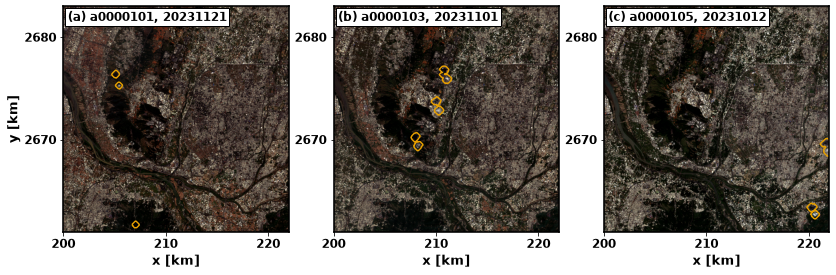

In [6]:
cand_files = [DATA / "candidates" / f"{n}.img" for n, _ in candidates]
fig, axes = plt.subplots(1, 3, figsize=(11.5, 4.6), constrained_layout=True)
for k, (ax, f, (name, item)) in enumerate(zip(axes, cand_files, candidates)):
    show_rgb(ax, f, limits)
    outline(ax, DATA / "cloud_masks" / f"{name}_cloud.tif", lambda a: a > 0, WONG[1])
    map_axes(ax, aoi_km)
    label(ax, f"({'abc'[k]}) {name}, {item.split('_')[2]}")
axes[0].set_ylabel("y [km]")
plt.show()

## 3. Prepare the step folders

### 3.1 Folders and parameter files

**What this cell does.** Each step runs in its own working folder and reads a
JSON parameter file there. The two functions from the demo script

- create `demo_output/step2/`, `step3/` and `step4/` (deleting earlier
  results) and copy each step's inputs into its folder, laid out as described
  in the README: the scenes and cloud masks for Step 2, the Pan scenes for
  Step 3, and the candidates, cloud masks, Pan scenes and a land/sea mask for
  Step 4 (the demo area is all land, so the mask is all ones);
- write `para.txt` (Step 2), `para_pan.txt` (Step 3) and `para_cld.txt`
  (Step 4).

The cell prints the Step 4 parameters. The two that decide which clouds are
filled are:

- `cloud_tolerance` (0.25): the largest share of a cloud patch that may be
  cloudy in a candidate scene for that candidate to be used;
- `ssim_threshold` (0.75): the smallest structural similarity (SSIM) between a
  candidate and the mosaic around the patch for that candidate to be used.

The other keys give the input and output paths, the resolutions (20 m XS,
10 m Pan), the bit depth (12) and the coordinate system.

In [7]:
demo.set_up_steps(WORK, DATA)
demo.write_configs(WORK)
# (paths shortened to demo_output/... for display)
print((S4 / "para_cld.txt").read_text().replace(str(WORK), "demo_output"))

{
 "res": "20.0",
 "trueBits": "12",
 "CandiImgPath": "demo_output/step4/cloud_database",
 "CldMaskPath": "demo_output/step4/cldDatabase",
 "MosaicImgAddress": "demo_output/step4/mosaic_xs.tif",
 "MosaicCldAddress": "demo_output/step4/mosaic_cloudmask.tif",
 "CandiMaskFolderName": "cloud_masks",
 "PanMosaicImgAddress": "demo_output/step4/mosaic_pan.tif",
 "pan_res": "10.0",
 "seaBorderAddress": "demo_output/step4/land_sea_mask.tif",
 "PanImgAddress": "demo_output/step4/raw_pan",
 "cloud_tolerance": "0.25",
 "ssim_threshold": "0.75",
 "canvas_crs": "EPSG:3826"
}


### 3.2 A function to run one step

**What this cell does.** It defines `run_step(script, folder)`, which runs one
step script as a separate Python process inside its working folder, exactly
as `python step2mosaic.py` in that folder would. The steps print a lot of
progress information; the function shows only the last few lines, and the
full output if the step fails.

In [8]:
def run_step(script, folder):
    result = subprocess.run([sys.executable, str(REPO / script)], cwd=folder,
                            capture_output=True, text=True)
    lines = [l for l in result.stdout.splitlines() if l.strip()]
    if result.returncode != 0:
        print("\n".join(lines[-40:]), result.stderr[-4000:])
        raise RuntimeError(f"{script} failed")
    print("\n".join(lines[-6:]))

## 4. Step 2: seamlines and the multispectral mosaic

**How Step 2 works.**

1. **Processing order.** It starts from the scene whose file name sorts first
   (`a0000001`, the middle strip; a different start can be set with the
   `startScene` key in `para.txt`) and adds the other scenes in order of
   distance from it. The order is written to `ProcessOrder.txt`.
2. **Seamline.** For each new scene, it looks at the overlap with the mosaic
   built so far and finds a path from one boundary crossing point to the other
   (Figure 1d). The path is the cheapest path through a graph of the overlap
   pixels. Cloud and no-data pixels are left out of the graph, so the path
   goes around clouds. Steps across strong edges in both images are cheap, so
   the path follows roads, rivers and field boundaries, where a seam is hard
   to see.
3. **Mosaic.** The new scene is added on its side of the seamline, with a
   narrow blend across it. The cloud masks are mosaicked the same way.

**What this cell does.** It runs Step 2 in `demo_output/step2/` (a few
seconds) and prints the processing order. The outputs are `mosaic_xs.tif`,
`mosaic_cloudmask.tif`, the seamlines (`*_seamline.img`), the blend weights
for Step 3 (`*_seamline_polygon.img`) and the bookkeeping files that Steps 3
and 4 read.

In [9]:
run_step("step2_mosaic/step2mosaic.py", S2)
print("processing order:", (S2 / "ProcessOrder.txt").read_text())

Writing result: a0000003 band: 2 to disk...
Writing result: a0000003 band: 3 to disk...
Writing result: a0000003 band: 4 to disk...
Writing cloud mask to disk...
All done!
Total time spent(hr): 0.0004025773611081402
processing order: ['a0000001.img', 'a0000005.img', 'a0000003.img']


### Figure 3: the result of Step 2

**What this cell does.** Panel (a) draws the XS mosaic in true colour with the
two seamlines (white with a black edge) and the outline of the mosaicked cloud
mask (orange). Panel (b) shows only the mosaicked cloud mask.

**What to look for.**

- The seamlines run through the overlaps from top to bottom, go around
  clouds and follow roads, rivers and field edges where they can.
- There is no visible step in brightness across the seamlines.
- The mosaic still contains clouds: Step 2 only joins the scenes. The cloud
  pixels in panel (b) are the ones that Step 4 will try to fill.

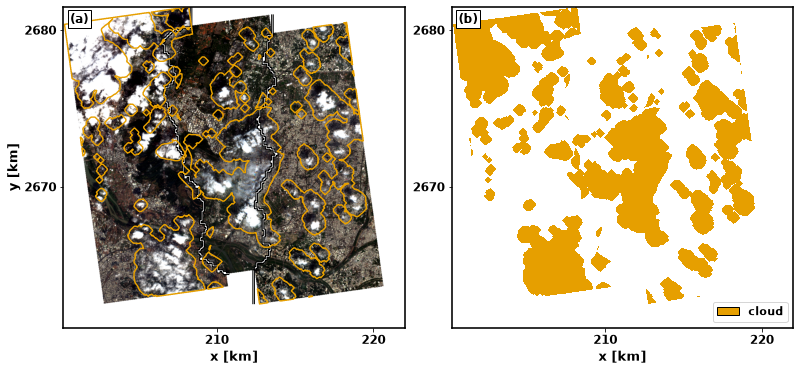

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5.6), constrained_layout=True)
ax = axes[0]
ext = show_rgb(ax, S2 / "mosaic_xs.tif", limits)
for f in sorted(S2.glob("*_seamline.img")):
    with rasterio.open(f) as src:
        seam = src.read(1) == 1
        e = extent_km(src)
    ax.imshow(np.ma.masked_where(~seam, seam), extent=e, cmap=mpl.colors.ListedColormap(["white"]),
              interpolation="none")
    outline(ax, f, lambda a: a == 1, "black", "-", 1.0)
outline(ax, S2 / "mosaic_cloudmask.tif", lambda a: a == 1, WONG[1])
map_axes(ax, ext); ax.set_ylabel("y [km]"); label(ax, "(a)")
ax = axes[1]
with rasterio.open(S2 / "mosaic_cloudmask.tif") as src:
    cm = src.read(1)
    e = extent_km(src)
ax.imshow(np.where(cm == 1, 1.0, np.nan), extent=e, cmap=mpl.colors.ListedColormap([WONG[1]]), interpolation="none")
map_axes(ax, ext); label(ax, "(b)")
ax.legend(handles=[Patch(facecolor=WONG[1], edgecolor="black", label="cloud")], loc="lower right")
plt.show()

## 5. Step 3: the panchromatic mosaic

**How Step 3 works.** It mosaics the Pan scenes with the seamlines that Step 2
found, using the blend weights Step 2 saved (`*_seamline_polygon.img`, already
at the Pan resolution). It does not search for new seamlines, so the XS and Pan
mosaics join the scenes in exactly the same places.

**What this cell does.** It copies the Step 2 files that Step 3 needs
(`ProcessOrder.txt`, `transform.npy`, `ImgInd.npy`, `allWindow.npy`,
`Union_gt.npy` and the blend weights) into `demo_output/step3/`, then runs
Step 3. The output is `mosaic_pan.tif` at 10 m.

In [11]:
demo.copy_matching(S2, S3, ["transform.npy", "ImgInd.npy", "allWindow.npy", "Union_gt.npy",
                            "ProcessOrder.txt", "*_seamline_polygon.img", "*_seamline_polygon.img.aux.xml"])
run_step("step3_pan_mosaic/mosaicPan_block_rs.py", S3)

Mosaicking and writing to disk...
Image Process Progress: 3 / 3
Clipping...
Mosaicking and writing to disk...
All done!
Total time spent(hr): 9.704504609948748e-05


### Figure 4: the Pan mosaic

**What this cell does.** It draws `mosaic_pan.tif` in grey scale, with a
2-98 % contrast stretch.

**What to look for.** The outline is the same as that of the XS mosaic in
Figure 3, and the scenes join without visible seams. The Pan mosaic has twice
the resolution of the XS mosaic (10 m against 20 m), so roads and field edges
are sharper. It still contains the clouds; Step 4 fills them in both mosaics.

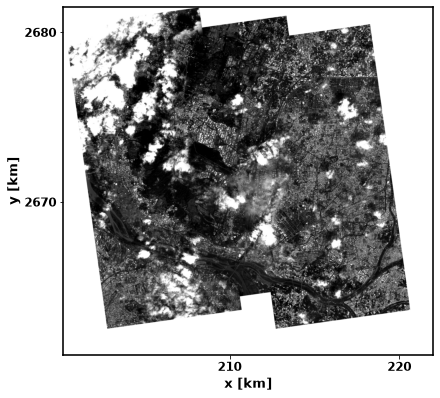

In [12]:
with rasterio.open(S3 / "mosaic_pan.tif") as src:
    pan = src.read(1).astype(float)
    e = extent_km(src)
valid = pan > 0
lo, hi = np.percentile(pan[valid], [2, 98])
fig, ax = plt.subplots(figsize=(6, 5.6), constrained_layout=True)
ax.imshow(np.where(valid, np.clip((pan - lo) / (hi - lo), 0, 1), np.nan), extent=e, cmap="gray")
map_axes(ax, e); ax.set_ylabel("y [km]")
plt.show()

## 6. Step 4: cloud filling

**How Step 4 works.**

1. It splits the cloud mask of the mosaic into separate cloud patches.
2. For each patch and each candidate scene, it computes the structural
   similarity (SSIM) between the candidate and the mosaic in the clear area
   around the patch, and the share of the patch that is cloudy in the
   candidate.
3. It tries the candidates from the highest SSIM down. The first one with SSIM
   of at least `ssim_threshold` and at most `cloud_tolerance` cloud in the
   patch fills it by Poisson blending (`cv2.seamlessClone`), which matches the
   brightness of the filled pixels to their surroundings. The same patch is
   filled in the Pan mosaic.
4. Patches that touch the edge of the mosaic, and patches for which no
   candidate passes both tests, stay unfilled and stay marked in the cloud mask.

**What this cell does.** It copies the Step 2 and Step 3 mosaics and the files
Step 4 needs into `demo_output/step4/`, keeps copies of the mosaics before
filling (`*_raw.tif`, for the comparisons below), runs Step 4, and prints the
share of the cloudy area that was filled.

In [13]:
demo.copy_matching(S2, S4, ["mosaic_xs.tif", "mosaic_cloudmask.tif", "allWindow.npy",
                            "transform.npy", "ProcessOrder.txt"])
demo.copy_matching(S3, S4, ["mosaic_pan.tif"])
for f in ("mosaic_xs.tif", "mosaic_pan.tif", "mosaic_cloudmask.tif"):
    shutil.copy(S4 / f, S4 / f.replace(".tif", "_raw.tif"))
run_step("step4_cloud_removal/step4cloud_removal.py", S4)

result = demo.check_results(S4)
print(f"Cloudy area filled: {result['fill_fraction']:.0%}")

cldzeroNum: 1
zeroExist: 0
right,up,left,low: 0 0 0 0
All done!
17 / 26  reconstructions of cloud-contaminated area
time(hr): 0.0008550037036022533
Cloudy area filled: 76%


### Figure 5: before and after Step 4

**What this cell does.** Panel (a) draws the XS mosaic before Step 4 with the
outline of the clouds (orange); panel (b) draws it after Step 4 with the
outline of the clouds that were left unfilled. Panel (c) classifies every
cloud pixel of the mosaic: filled (blue) or left unfilled (orange); grey is the
rest of the mosaic.

**What to look for.**

- In (b), most clouds of (a) are gone, and the filled areas match their
  surroundings in colour and brightness.
- In (c), the unfilled clouds (orange) are mainly the large patches in the
  north-west that touch the edge of the mosaic; Step 4 does not fill those.
- Some filled patches still look slightly hazy. The cloud masks come from the
  Sentinel-2 scene classification, which does not catch all haze; the haze
  outside the masks stays in the mosaic.

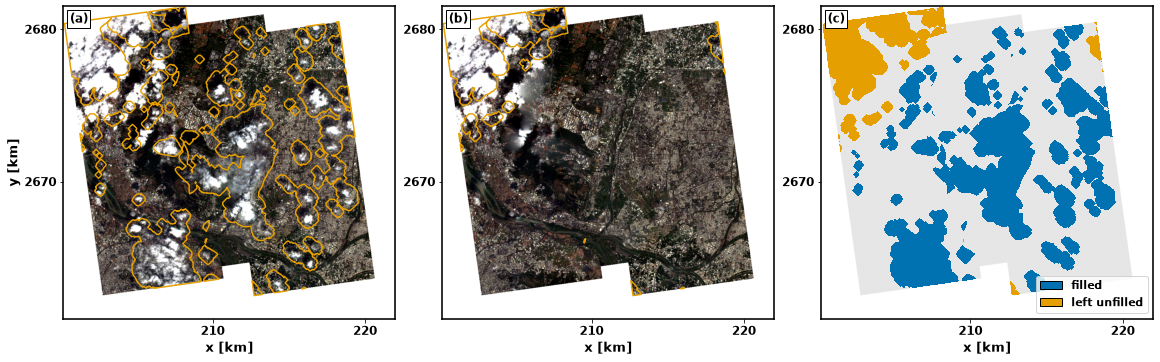

In [14]:
with rasterio.open(S4 / "mosaic_cloudmask_raw.tif") as src:
    before = src.read(1) == 1
    e = extent_km(src)
with rasterio.open(S4 / "mosaic_cloudmask.tif") as src:
    after = src.read(1) == 1
status = np.full(before.shape, np.nan)
status[before & ~after] = 0          # filled
status[after] = 1                    # left unfilled

fig, axes = plt.subplots(1, 3, figsize=(16, 5.6), constrained_layout=True)
for k, (ax, f) in enumerate(zip(axes[:2], ["mosaic_xs_raw.tif", "mosaic_xs.tif"])):
    show_rgb(ax, S4 / f, limits)
    mask = "mosaic_cloudmask_raw.tif" if k == 0 else "mosaic_cloudmask.tif"
    outline(ax, S4 / mask, lambda a: a == 1, WONG[1])
    map_axes(ax, e); label(ax, f"({'ab'[k]})")
axes[0].set_ylabel("y [km]")
ax = axes[2]
with rasterio.open(S4 / "mosaic_xs_raw.tif") as src:
    footprint = np.all(src.read() > 0, axis=0)
ax.imshow(np.where(footprint, 0.9, np.nan), extent=e, cmap="gray", vmin=0, vmax=1)
ax.imshow(status, extent=e, cmap=mpl.colors.ListedColormap([WONG[5], WONG[1]]), vmin=0, vmax=1,
          interpolation="none")
map_axes(ax, e); label(ax, "(c)")
ax.legend(handles=[Patch(facecolor=WONG[5], edgecolor="black", label="filled"),
                   Patch(facecolor=WONG[1], edgecolor="black", label="left unfilled")], loc="lower right")
plt.show()

### Before/after slider (as in CloudPeel)

**What this cell does.** It puts the XS mosaic before Step 4 and after Step 4 on
top of each other. Drag the slider: the part left of the white line shows the
mosaic before Step 4, the part right of it the mosaic after. This is the same
comparison as the [CloudPeel explorer](https://buckai-observatory.org/Automated-Cloud-Removal-and-Seamless-Satellite-Image-Mosaicking-Pipeline/cloudpeel/), for this
run.

The slider needs the notebook to be running (on Colab, in JupyterLab or in
Jupyter Notebook). In a static view of the notebook, such as on GitHub, only
the first frame is shown.


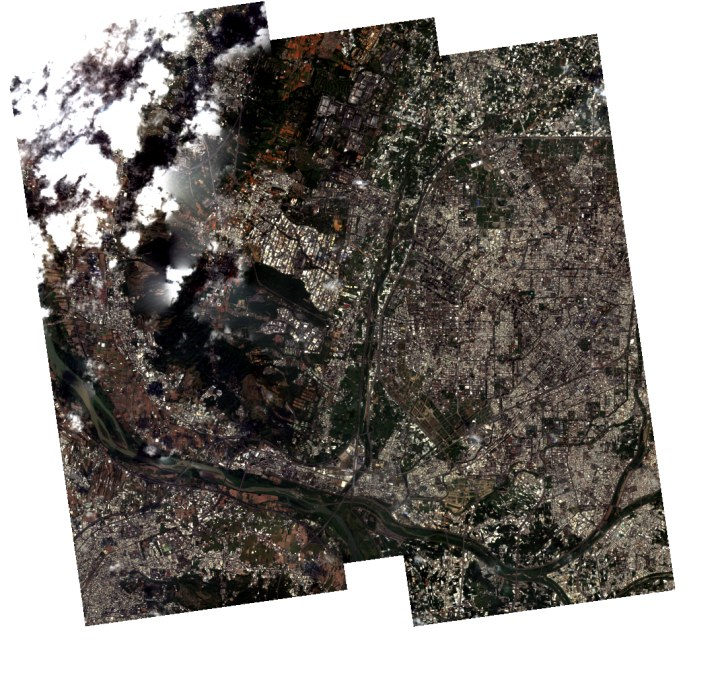
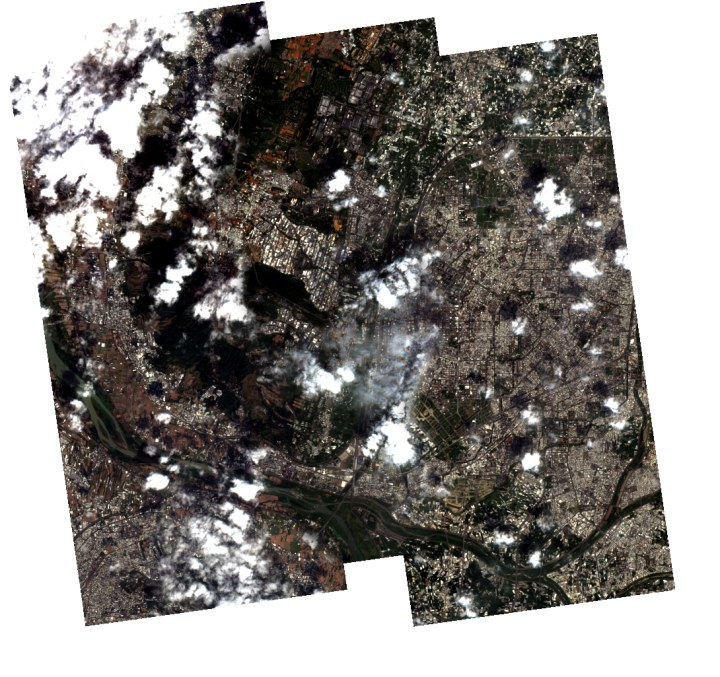

In [15]:
def jpeg_base64(path, limits, width=720):
    """True-colour JPEG of a raster (no-data white), resized to *width* pixels, as base64 text."""
    rgba, _ = rgb_array(path, limits)
    rgb = rgba[..., :3] * rgba[..., 3:] + (1 - rgba[..., 3:])        # white where no data
    height = round(rgb.shape[0] * width / rgb.shape[1])
    small = cv2.resize((rgb * 255).astype(np.uint8), (width, height), interpolation=cv2.INTER_AREA)
    ok, buffer = cv2.imencode(".jpg", cv2.cvtColor(small, cv2.COLOR_RGB2BGR), [cv2.IMWRITE_JPEG_QUALITY, 88])
    return base64.b64encode(buffer.tobytes()).decode()

def before_after_slider(before_file, after_file, limits, width=720):
    uid = "s" + uuid.uuid4().hex[:8]
    b, a = jpeg_base64(before_file, limits, width), jpeg_base64(after_file, limits, width)
    tag = "position:absolute;top:8px;padding:2px 6px;background:#fff;border:1.5px solid #000;font:bold 13px sans-serif"
    return HTML(f"""
<div style="width:{width}px;max-width:100%">
  <div style="position:relative">
    <img src="data:image/jpeg;base64,{a}" style="display:block;width:100%">
    <img id="{uid}b" src="data:image/jpeg;base64,{b}"
         style="position:absolute;top:0;left:0;width:100%;clip-path:inset(0 50% 0 0)">
    <div id="{uid}l" style="position:absolute;top:0;bottom:0;left:50%;width:3px;margin-left:-1px;background:#fff;box-shadow:0 0 0 1px #000"></div>
    <span style="{tag};left:8px">before Step 4</span>
    <span style="{tag};right:8px">after Step 4</span>
  </div>
  <input type="range" min="0" max="100" value="50" style="width:100%"
         oninput="document.getElementById('{uid}b').style.clipPath='inset(0 '+(100-this.value)+'% 0 0)';
                  document.getElementById('{uid}l').style.left=this.value+'%'">
</div>""")

display(before_after_slider(S4 / "mosaic_xs_raw.tif", S4 / "mosaic_xs.tif", limits))

### The fill log

**What this cell does.** It shows the first rows of `fill_log.csv`, which Step 4
writes in its folder. There is one row for each candidate tried for each cloud
patch:

| Column | Meaning |
|---|---|
| `window`, `patch` | the cloud patch (patch file name, within one scene window) |
| `candidate` | the candidate scene tried (empty if none passed the SSIM threshold) |
| `ssim` | similarity between the candidate and the mosaic around the patch |
| `clear_fraction` | share of the patch that is clear in the candidate |
| `filled` | `yes` if this candidate filled the patch |
| `pixels` | size of the patch in pixels |
| `note` | why a candidate was not used |
| `x_min` ... `y_max` | bounds of the patch in map coordinates |

The log is useful to see why a particular cloud was not filled.

In [16]:
log = pd.read_csv(S4 / "fill_log.csv")
log.head(10)

,window,patch,candidate,ssim,clear_fraction,filled,pixels,note,x_min,y_min,x_max,y_max
0,0,10_cld.img,a0000103.img,0.9867,1.0000,yes,1498,NaN,208500.0,2677420.0,209800.0,2678620.0
1,0,11_cld.img,a0000103.img,0.8877,0.9482,yes,127705,NaN,205780.0,2665800.0,214620.0,2678880.0
2,0,12_cld.img,a0000103.img,0.9880,1.0000,yes,1352,NaN,212820.0,2677940.0,214020.0,2679160.0
3,0,13_cld.img,a0000103.img,0.8387,1.0000,yes,1882,NaN,212520.0,2679060.0,213880.0,2680460.0
4,0,14_cld.img,a0000103.img,0.9757,1.0000,yes,5448,NaN,211080.0,2677780.0,213140.0,2680520.0
5,0,15_cld.img,a0000103.img,0.8277,1.0000,yes,92622,NaN,213780.0,2666580.0,219880.0,2680680.0
6,0,16_cld.img,NaN,0.6458,NaN,no,5613,no candidate reaches ssim_threshold,217260.0,2677600.0,218980.0,2680820.0
7,0,17_cld.img,a0000103.img,0.8948,NaN,no,20776,cloud reaches the edge of the candidate overla...,205400.0,2676900.0,208800.0,2681000.0
8,0,17_cld.img,a0000105.img,0.8852,NaN,no,20776,cloud reaches the edge of the candidate overla...,205400.0,2676900.0,208800.0,2681000.0
9,0,17_cld.img,a0000101.img,0.8792,NaN,no,20776,cloud reaches the edge of the candidate overla...,205400.0,2676900.0,208800.0,2681000.0


## 7. Next steps

- **The products** are in `demo_output/step4/`: `mosaic_xs.tif`,
  `mosaic_pan.tif` and `mosaic_cloudmask.tif` (0 = clear or filled, 1 = cloud
  left unfilled, 10/20 = flagged by the cloud mask of the candidate used). On
  Colab, download them with the file browser on the left.
- **Change the parameters.** Edit `cloud_tolerance` or `ssim_threshold` in
  `demo_output/step4/para_cld.txt` and rerun section 6 to see how the fill
  changes. The [CloudPeel explorer](https://buckai-observatory.org/Automated-Cloud-Removal-and-Seamless-Satellite-Image-Mosaicking-Pipeline/cloudpeel/) shows this for several
  regions without running anything.
- **Your own area.** The notebook
  [`your_own_area_columbus.ipynb`](your_own_area_columbus.ipynb) does the same
  for an area and season you choose (Columbus, Ohio, in summer 2024), finding
  and downloading the scenes with geoai-datacubes.
- **Your own scenes.** The README of each step describes the inputs and
  parameter files; the [documentation website](https://buckai-observatory.org/Automated-Cloud-Removal-and-Seamless-Satellite-Image-Mosaicking-Pipeline/) has all of them.